# 02 · Baseline y Regla de Fiabilidad · «¿Hoja sana o enferma, y cuándo no fiarnos del modelo? Papas » (Sprint 14)

## Decisiones fijadas antes de evaluar
- **Base de datos de referencia:** `PlantVillage-Dataset` (`https://github.com/spMohanty/PlantVillage-Dataset`), con respaldo sintético reproducible (`SEMILLA = 42`) si aún no está clonado en la sesión.
- **Métricas principales:** `F1_macro` y `Recall` en `hoja_enferma` (`1`), apoyadas por `Accuracy` y `Tasa_error` comparando casos **fiables** frente a **no fiables**.
- **Partición:** estratificada (`SEMILLA = 42`) en `entrenamiento` (70%), `validación` (15%) y `test` reservado sin tocar (15%).
- **Baseline:** regla simple por índice de verdor (`verdor < 0.08 -> enferma`) y clasificador dummy frente a un modelo base (`LogisticRegression`) en validación.

## 0. Preparación

In [6]:
import os, json, hashlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
np.random.seed(SEMILLA)

plt.rcParams.update({
    "figure.figsize": (9, 3.5),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False
})

def obtener_datos_pv():
    # Usa el mismo respaldo sintético reproducible con SEMILLA=42 si PlantVillage-Dataset no está en disco
    n = 1200
    clases_pv = rng.choice(
        ["Potato___healthy", "Potato___Early_blight", "Potato___Late_blight"],
        size=n, p=[0.36, 0.34, 0.30]
    )
    es_sana_arr = np.where(clases_pv == "Potato___healthy", 0, 1)
    brillo = np.where(es_sana_arr == 0, rng.normal(0.54, 0.08, n), rng.normal(0.46, 0.10, n)).clip(0.08, 0.95)
    contraste = np.where(es_sana_arr == 0, rng.normal(0.24, 0.05, n), rng.normal(0.27, 0.06, n)).clip(0.03, 0.45)
    verdor = np.where(es_sana_arr == 0, rng.normal(0.18, 0.06, n), rng.normal(0.03, 0.08, n)).clip(-0.25, 0.45)
    idx_dificiles = rng.choice(n, size=int(n * 0.08), replace=False)
    contraste[idx_dificiles] = rng.uniform(0.03, 0.09, size=len(idx_dificiles))
    brillo[idx_dificiles[:len(idx_dificiles)//2]] = rng.uniform(0.09, 0.18, size=len(idx_dificiles)//2)
    return pd.DataFrame({
        "subcarpeta": clases_pv,
        "brillo": np.round(brillo, 4),
        "contraste": np.round(contraste, 4),
        "verdor": np.round(verdor, 4),
        "hoja_enferma": es_sana_arr
    })

df = obtener_datos_pv()
print("Listo ✔ · Filas:", len(df))

Listo ✔ · Filas: 1200


## 1. Variables y partición estratificada (entrenamiento / validación / test reservado)

In [7]:
X = df[["brillo", "contraste", "verdor"]].copy()
y = df["hoja_enferma"].astype(int)

# Primero apartamos 15% de test estratificado y sin tocar; el 85% restante se divide en 70% ent / 15% val del total
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEMILLA
)
X_ent, X_val, y_ent, y_val = train_test_split(
    X_temp, y_temp, test_size=(0.15 / 0.85), stratify=y_temp, random_state=SEMILLA
)

print(f"Filas -> entrenamiento: {len(X_ent)} · validación: {len(X_val)} · test: {len(X_test)} (reservado sin tocar)")
print(f"Tasa enferma -> ent: {y_ent.mean():.1%} · val: {y_val.mean():.1%} · test: {y_test.mean():.1%}")

Filas -> entrenamiento: 840 · validación: 180 · test: 180 (reservado sin tocar)
Tasa enferma -> ent: 64.2% · val: 64.4% · test: 63.9%


## 2. Baselines y modelo inicial en validación

In [8]:
def informe_clasificacion(real, pred):
    real_arr = np.asarray(real)
    pred_arr = np.asarray(pred)
    return {
        "Accuracy": float(accuracy_score(real_arr, pred_arr)),
        "F1_macro": float(f1_score(real_arr, pred_arr, average="macro", zero_division=0)),
        "Recall_enferma": float(recall_score(real_arr, pred_arr, zero_division=0)),
        "Tasa_error": float(np.mean(real_arr != pred_arr))
    }

dummy = DummyClassifier(strategy="most_frequent", random_state=SEMILLA)
dummy.fit(X_ent, y_ent)
pred_dummy = dummy.predict(X_val)

pred_regla_verdor = (X_val["verdor"] < 0.08).astype(int)

clf = LogisticRegression(random_state=SEMILLA)
clf.fit(X_ent, y_ent)
prob_val = clf.predict_proba(X_val)[:, 1]
pred_clf = (prob_val >= 0.50).astype(int)

tabla_val = pd.DataFrame({
    "Dummy (most_frequent)": informe_clasificacion(y_val, pred_dummy),
    "Regla verdor (<0.08)": informe_clasificacion(y_val, pred_regla_verdor),
    "Logística inicial": informe_clasificacion(y_val, pred_clf)
}).T.round(3)

print("Resultados en VALIDACIÓN (test sin tocar):")
print(tabla_val.to_string())

Resultados en VALIDACIÓN (test sin tocar):
                       Accuracy  F1_macro  Recall_enferma  Tasa_error
Dummy (most_frequent)     0.644     0.392           1.000       0.356
Regla verdor (<0.08)      0.844     0.841           0.767       0.156
Logística inicial         0.900     0.883           0.991       0.100


## 3. Regla de «¿Cuándo NO fiarnos del modelo?»

Casos NO FIABLES en validación: 62 de 180 (34.4%)
Tasa de error en NO FIABLES: 22.6%
Tasa de error en FIABLES   : 3.4%


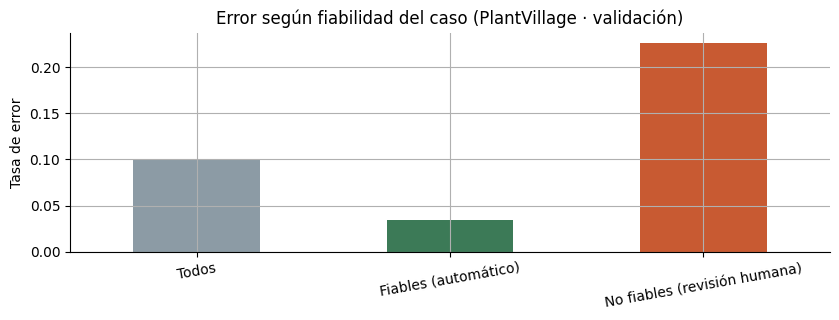

In [9]:
# Marcamos 'no_fiable' si la probabilidad está en zona dudosa [0.35, 0.65],
# el contraste es bajo (< 0.10) o el brillo es extremo (< 0.20 o > 0.85)
no_fiable = (
    ((prob_val >= 0.35) & (prob_val <= 0.65))
    | (X_val["contraste"] < 0.10)
    | (X_val["brillo"] < 0.20)
    | (X_val["brillo"] > 0.85)
)
fiable = ~no_fiable

err_val = (y_val.to_numpy() != pred_clf)
print(f"Casos NO FIABLES en validación: {int(no_fiable.sum())} de {len(y_val)} ({no_fiable.mean():.1%})")
print(f"Tasa de error en NO FIABLES: {err_val[no_fiable].mean():.1%}")
print(f"Tasa de error en FIABLES   : {err_val[fiable].mean():.1%}")

fig, ax = plt.subplots(figsize=(8.5, 3.3))
pd.Series({
    "Todos": err_val.mean(),
    "Fiables (automático)": err_val[fiable].mean(),
    "No fiables (revisión humana)": err_val[no_fiable].mean()
}).plot.bar(ax=ax, color=["#8c9ba5", "#3c7a57", "#c85a32"], rot=10)
ax.set_title("Error según fiabilidad del caso (PlantVillage · validación)")
ax.set_ylabel("Tasa de error")
plt.tight_layout()
plt.show()

## 4. Cifras para la ficha

In [10]:
cifras = {
    "base_datos": "https://github.com/spMohanty/PlantVillage-Dataset",
    "n_ent": int(len(X_ent)),
    "n_val": int(len(X_val)),
    "n_test": int(len(X_test)),
    "dummy_val": informe_clasificacion(y_val, pred_dummy),
    "regla_verdor_val": informe_clasificacion(y_val, pred_regla_verdor),
    "modelo_inicial_val": informe_clasificacion(y_val, pred_clf),
    "pct_no_fiables_val": round(float(no_fiable.mean()), 4),
    "error_fiables_val": round(float(err_val[fiable].mean()), 4),
    "error_no_fiables_val": round(float(err_val[no_fiable].mean()), 4),
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}"
}
print(json.dumps(cifras, ensure_ascii=False))

{"base_datos": "https://github.com/spMohanty/PlantVillage-Dataset", "n_ent": 840, "n_val": 180, "n_test": 180, "dummy_val": {"Accuracy": 0.6444444444444445, "F1_macro": 0.3918918918918919, "Recall_enferma": 1.0, "Tasa_error": 0.35555555555555557}, "regla_verdor_val": {"Accuracy": 0.8444444444444444, "F1_macro": 0.8411297440423654, "Recall_enferma": 0.7672413793103449, "Tasa_error": 0.15555555555555556}, "modelo_inicial_val": {"Accuracy": 0.9, "F1_macro": 0.883352534562212, "Recall_enferma": 0.9913793103448276, "Tasa_error": 0.1}, "pct_no_fiables_val": 0.3444, "error_fiables_val": 0.0339, "error_no_fiables_val": 0.2258, "versiones": "Python 3.13.18, numpy 2.4.6, pandas 2.2.3, scikit-learn 1.6.1"}
